# 03 — Task 3: Cross-dataset generalization (20 %)

* **KDEF→FER:** the best Task 2 configuration is re-trained on the preprocessed KDEF images and
  evaluated directly on FER2013 PrivateTest.
* **FER→KDEF:** the same configuration trained on FER2013 and evaluated on the KDEF test subjects.
* Both directions use the same FER image format (48×48 gray, same normalization inside the
  feature extractors), as required by the experimental protocol.

Then:
1. a **feature transfer** table (which representation survives the domain change);
2. a **domain-shift measurement** (how easily a classifier can tell the two datasets apart);
3. a **domain-adaptation** table: each row removes one source of shift — (i) crop/alignment,
   (ii) resolution/quality, (iii) intensity — or aligns the feature distributions (per-domain
   standardization, CORAL), plus all of them combined.

Adaptations only use **unlabelled** statistics of the target domain's *training* split, never
the test labels or the test images themselves.

In [1]:
# Common setup + evaluation helpers (identical in every notebook of the project)
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedShuffleSplit

sys.path.insert(0, str(Path.cwd()))
try:
    from src import features as F
except ImportError:  # fuzzy environment (no OpenCV/dlib): only cached features are used there
    from types import SimpleNamespace
    F = SimpleNamespace(EMOTIONS=["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"],
                        CACHE_DIR=Path("data") / "cache")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# SMOKE=1 (environment variable) runs everything on small subsets with reduced grids, to
# check the notebook end-to-end in minutes. The delivered results use SMOKE=0 (default).
SMOKE = os.environ.get("SMOKE", "0") == "1"
SEED = 42
N_JOBS = -1
EMO = F.EMOTIONS
RESULTS_DIR, FIG_DIR, MODEL_DIR = Path("results"), Path("figures"), Path("models")
for d in (RESULTS_DIR, FIG_DIR, MODEL_DIR, F.CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
print(f"SMOKE={SMOKE}")


def metrics(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "bal_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(7), zero_division=0)}


def per_class_f1(y_true, y_pred):
    return pd.Series(f1_score(y_true, y_pred, average=None, labels=range(7), zero_division=0), index=EMO)


_RESULTS = {}


def reset_results(task):
    """Start a fresh results/<task>.csv for this run of the notebook."""
    _RESULTS[task] = []
    (RESULTS_DIR / f"{task}.csv").unlink(missing_ok=True)


def log_result(task, y_true, y_pred, **info):
    """Append one evaluation row (fixed schema) to results/<task>.csv and return it."""
    row = {**info, **{k: round(v, 4) for k, v in metrics(y_true, y_pred).items()}, "n": len(y_true)}
    _RESULTS.setdefault(task, []).append(row)
    pd.DataFrame(_RESULTS[task]).to_csv(RESULTS_DIR / f"{task}.csv", index=False)
    return row


def fixed_table(df, index, columns, value, index_order, column_order):
    """Pivot to a table with a FIXED row/column layout (same x and y in every task)."""
    t = df.pivot_table(index=index, columns=columns, values=value, aggfunc="first")
    return t.reindex(index=index_order, columns=column_order)


def save_table(df, name, float_format="%.3f"):
    """Save a table as CSV and as a LaTeX tabular (pasted into report/*.md)."""
    df.to_csv(RESULTS_DIR / f"{name}.csv")
    with open(RESULTS_DIR / f"{name}.tex", "w", encoding="utf-8") as f:
        f.write(df.to_latex(float_format=float_format, na_rep="--"))
    return df


def plot_cm(y_true, y_pred, title="", ax=None, normalize=True):
    cm = confusion_matrix(y_true, y_pred, labels=range(7), normalize="true" if normalize else None)
    ax = ax or plt.subplots(figsize=(4.2, 3.6))[1]
    sns.heatmap(cm, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=[e[:3] for e in EMO], yticklabels=[e[:3] for e in EMO], ax=ax,
                vmin=0, vmax=1 if normalize else None, annot_kws={"size": 7})
    ax.set_title(title, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    return ax


def plot_cm_grid(items, fname, ncols=4):
    """items: list of (title, y_true, y_pred). Saved in figures/ for the report appendix."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (title, yt, yp) in zip(axes.ravel(), items):
        plot_cm(yt, yp, title, ax=ax)
    for ax in axes.ravel()[len(items):]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


def stratified_subset(y, n, seed=SEED):
    """Indices of a stratified random subset of size n (all indices if n >= len(y))."""
    if n is None or n >= len(y):
        return np.arange(len(y))
    sss = StratifiedShuffleSplit(n_splits=1, train_size=n, random_state=seed)
    return np.sort(next(sss.split(np.zeros(len(y)), y))[0])


def scores(model, X):
    """Class scores for confidence analyses (predict_proba, else softmax(decision_function))."""
    if hasattr(model, "predict_proba"):
        try:
            return model.predict_proba(X)
        except AttributeError:
            pass
    d = model.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def save_bundle(name, model, spec, **extra):
    """Persist a FITTED model together with the feature spec needed to use it (demo, other tasks)."""
    bundle = {"model": model, "spec": spec, "labels": EMO, **extra}
    joblib.dump(bundle, MODEL_DIR / f"{name}.pkl", compress=3)
    print(f"saved models/{name}.pkl")


def show_images(imgs, titles=None, ncols=8, size=1.5, fname=None, suptitle=None, cmap="gray"):
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 1.15 * nrows), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < len(imgs):
            ax.imshow(imgs[i], cmap=None if imgs[i].ndim == 3 else cmap, vmin=0, vmax=255)
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    if fname:
        fig.savefig(FIG_DIR / fname)
    plt.show()

SMOKE=False


In [2]:
# Classifiers, feature sets and the tuning protocol (shared by notebooks 01, 02, 03, 05)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit, GroupKFold
from sklearn.base import clone
from src.gpu_svm import GPUKernelSVC, device, MAX_KERNEL_N

# The RBF-SVM is GPUKernelSVC: the same libsvm solver as SVC(kernel="rbf"), but the kernel matrix is
# computed with PyTorch on the GPU (CUDA) — identical predictions, ~30x faster (see src/gpu_svm.py).
print("kernel computations on:", device())
MODELS = ["LR", "SVM", "RF"]               # fixed row order of every result grid
FEATURES = ["HOG", "LM", "PCA", "HOG+LM"]   # fixed column order of every result grid
FEATURE_BLOCKS = {"HOG": ["hog"], "LM": ["lm"], "PCA": ["pix"], "HOG+LM": ["hog", "lm"]}
N_TREES = 100 if SMOKE else 300
# one GPU: run SVM grid candidates one after the other (each holds an n x n kernel matrix)
SVM_JOBS = 1 if device() == "cuda" else 4


def base_estimator(model, n_jobs=1):
    if model == "LR":
        return LogisticRegression(max_iter=3000, random_state=SEED)
    if model == "SVM":
        return GPUKernelSVC(gamma="scale", cache_size=2000, random_state=SEED)
    if model == "RF":
        return RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", n_jobs=n_jobs, random_state=SEED)
    raise ValueError(model)


def make_pipeline(model, feature, n_jobs=1):
    """StandardScaler -> [PCA (eigenfaces, only for raw pixels)] -> classifier."""
    steps = [("scaler", StandardScaler())]
    if feature == "PCA":
        steps.append(("pca", PCA(n_components=100, whiten=True, random_state=SEED)))
    steps.append(("clf", base_estimator(model, n_jobs)))
    return Pipeline(steps)


if SMOKE:
    GRIDS = {"LR": {"clf__C": [0.1, 1.0], "clf__class_weight": ["balanced"]},
             "SVM": {"clf__C": [1, 10], "clf__class_weight": ["balanced"]},
             "RF": {"clf__max_depth": [None], "clf__class_weight": [None, "balanced_subsample"]}}
    PCA_GRID = {"pca__n_components": [60]}
else:
    GRIDS = {"LR": {"clf__C": [0.01, 0.1, 1.0], "clf__class_weight": [None, "balanced"]},
             "SVM": {"clf__C": [1, 3, 10], "clf__class_weight": [None, "balanced"]},
             "RF": {"clf__max_depth": [None, 25], "clf__min_samples_leaf": [1, 3],
                    "clf__class_weight": [None, "balanced_subsample"]}}
    PCA_GRID = {"pca__n_components": [60, 120]}


def param_grid(model, feature):
    return {**GRIDS[model], **(PCA_GRID if feature == "PCA" else {})}


def tune_predefined(model, feature, X_tr, y_tr, X_va, y_va, n_search):
    """Grid search: fit on (a stratified subset of) Training, score macro-F1 on PublicTest."""
    idx = stratified_subset(y_tr, n_search)
    X = np.vstack([X_tr[idx], X_va]); y = np.concatenate([y_tr[idx], y_va])
    ps = PredefinedSplit(np.concatenate([-np.ones(len(idx)), np.zeros(len(y_va))]))
    gs = GridSearchCV(make_pipeline(model, feature), param_grid(model, feature),
                      scoring="f1_macro", cv=ps, n_jobs=SVM_JOBS if model == "SVM" else N_JOBS, refit=False)
    gs.fit(X, y)
    return gs.best_params_, gs.best_score_


def tune_groupkfold(model, feature, X, y, groups, n_splits=5):
    """Subject-independent CV (no validation split exists for KDEF)."""
    gs = GridSearchCV(make_pipeline(model, feature), param_grid(model, feature), scoring="f1_macro",
                      cv=GroupKFold(n_splits=n_splits), n_jobs=SVM_JOBS if model == "SVM" else N_JOBS, refit=False)
    gs.fit(X, y, groups=groups)
    std = gs.cv_results_["std_test_score"][gs.best_index_]
    return gs.best_params_, gs.best_score_, std


def fit_final(model, feature, params, X, y, sample_weight=None):
    pipe = make_pipeline(model, feature, n_jobs=N_JOBS).set_params(**params)
    fit_kw = {"clf__sample_weight": sample_weight} if sample_weight is not None else {}
    return pipe.fit(X, y, **fit_kw)

kernel computations on: cuda


In [3]:
# Cached datasets and features (written by 00_data_preparation.ipynb)
# Dataset keys: "fer_gray", "fer_aligned", "kdef_m0.0_gray" ... "kdef_m0.3_gray", "kdef_m0.2_rgb",
# "kdef_m0.2_gray_aligned". Splits: FER train/val/test, KDEF train/test.
import re
FEATURE_BLOCKS.update({"GEO": ["geo"]})
_DS = {}


def images(key, split):
    if key not in _DS:
        _DS[key] = dict(np.load(F.CACHE_DIR / f"{key}.npz", allow_pickle=True))
    return _DS[key][f"X_{split}"], _DS[key][f"y_{split}"]


def meta(key, field, split):
    images(key, split)
    return _DS[key][f"{field}_{split}"]


def crop_margin(key):
    """Crop margin of a dataset (KDEF keys encode it, e.g. 'kdef_m0.2_gray'; FER crops: 0)."""
    m = re.search(r"_m([0-9.]+)_", key)
    return float(m.group(1)) if m else 0.0


def landmarks(key, split, variant="gray"):
    X, _ = images(key, split)
    vt = "" if variant == "gray" else f"-{variant}"
    return F.cached(f"{key}{vt}_{split}_pts",
                    lambda: F.extract_landmarks(F.apply_variant(X, variant), margin=crop_margin(key)))


def features(key, split, feature, variant="gray", hog=None):
    """Feature matrix of a cached dataset split (computed once, then loaded from data/cache)."""
    if feature == "HOG+LM":
        return np.hstack([features(key, split, "HOG", variant, hog), features(key, split, "LM", variant)])
    X, _ = images(key, split)
    vt = "" if variant == "gray" else f"-{variant}"
    ht = "" if not hog else "_o{}c{}".format(hog["orientations"], hog["pixels_per_cell"][0])
    spec = {"variant": variant, "blocks": FEATURE_BLOCKS[feature], "hog": hog or {}}
    pts = landmarks(key, split, variant) if feature in ("LM", "GEO") else None
    return F.cached(f"{key}{vt}_{split}_{feature}{ht}", lambda: F.extract_feature_set(X, spec, pts=pts))


def spec_for(feature, variant="gray", hog=None, crop_margin=0.0):
    """Feature spec stored in a model bundle (lets demo_emotion.py rebuild the features)."""
    blocks = sum((FEATURE_BLOCKS[f] for f in feature.split("+")), [])
    return {"variant": variant, "blocks": blocks, "hog": hog or {}, "feature": feature, "crop_margin": crop_margin}

In [4]:
for t in ("task3_transfer", "task3_features", "task3_adapt", "task3_margin", "task3_domain_clf"):
    reset_results(t)
t1 = json.load(open(RESULTS_DIR / "task1_best.json"))
t2 = json.load(open(RESULTS_DIR / "task2_best.json"))
MODEL, FEAT = t2["model"], t2["feature"]
print(f"Best Task 2 configuration: {MODEL} + {FEAT}")


def params_for(source, model, feat):
    """Hyper-parameters tuned in the SOURCE domain (Task 1 for FER, Task 2 for KDEF)."""
    allp = (t1 if source == "FER" else t2)["all_params"]
    return allp.get(f"{model}|{feat}", allp.get(f"{model}|LM", {}))


y_fer_tr_full = images("fer_gray", "train")[1]
TR_FULL = stratified_subset(y_fer_tr_full, 3000 if SMOKE else None)
TR_CROSS = stratified_subset(y_fer_tr_full, 2000 if SMOKE else 10000)   # FER source size for the many adaptation rows
TE_FER = stratified_subset(images("fer_gray", "test")[1], 1500 if SMOKE else None)

Best Task 2 configuration: LR + HOG+LM


## 1. Main transfer experiment (2 × 2 train/test matrix)

macro_f1


test,FER test,KDEF test
train,,
FER,0.426,0.386
KDEF,0.169,0.637
KDEF (all 980),0.188,NaN


acc


test,FER test,KDEF test
train,,
FER,0.492,0.444
KDEF,0.209,0.638
KDEF (all 980),0.228,NaN


bal_acc


test,FER test,KDEF test
train,,
FER,0.424,0.444
KDEF,0.205,0.638
KDEF (all 980),0.217,NaN


saved models/task3_kdef_to_fer.pkl


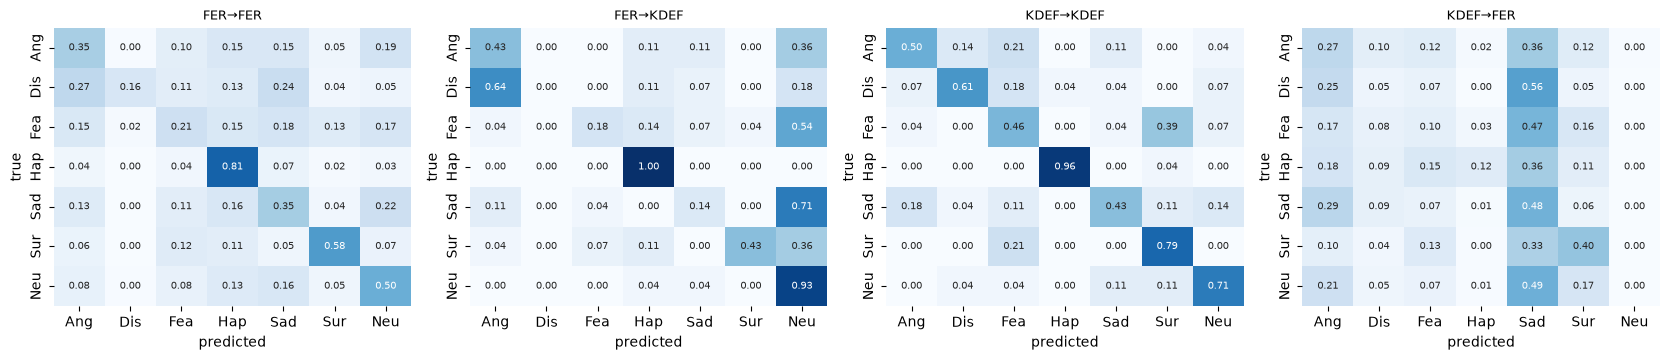

In [5]:
def domain_data(domain, split, feat, key=None, variant="gray"):
    key = key or ("fer_gray" if domain == "FER" else "kdef_m0.2_gray")
    X, y = features(key, split, feat, variant), images(key, split)[1]
    if domain == "FER" and split == "train":
        return X, y
    if domain == "FER" and split == "test":
        return X[TE_FER], y[TE_FER]
    return X, y


Xf_tr, yf_tr = domain_data("FER", "train", FEAT); Xf_tr, yf_tr = Xf_tr[TR_FULL], yf_tr[TR_FULL]
Xf_te, yf_te = domain_data("FER", "test", FEAT)
Xk_tr, yk_tr = domain_data("KDEF", "train", FEAT)
Xk_te, yk_te = domain_data("KDEF", "test", FEAT)
Xk_all = np.vstack([Xk_tr, Xk_te]); yk_all = np.concatenate([yk_tr, yk_te])

fer_model = fit_final(MODEL, FEAT, params_for("FER", MODEL, FEAT), Xf_tr, yf_tr)
kdef_model = fit_final(MODEL, FEAT, params_for("KDEF", MODEL, FEAT), Xk_tr, yk_tr)
kdef_all_model = fit_final(MODEL, FEAT, params_for("KDEF", MODEL, FEAT), Xk_all, yk_all)
P = {}
for train_name, mdl in [("FER", fer_model), ("KDEF", kdef_model), ("KDEF (all 980)", kdef_all_model)]:
    for test_name, X, y in [("FER test", Xf_te, yf_te), ("KDEF test", Xk_te, yk_te)]:
        if train_name == "KDEF (all 980)" and test_name == "KDEF test":
            continue  # test subjects are in the training set
        P[(train_name, test_name)] = mdl.predict(X)
        log_result("task3_transfer", y, P[(train_name, test_name)], train=train_name, test=test_name, model=MODEL, feature=FEAT)
tr = pd.read_csv(RESULTS_DIR / "task3_transfer.csv")
for m in ("macro_f1", "acc", "bal_acc"):
    t = save_table(fixed_table(tr, "train", "test", m, ["FER", "KDEF", "KDEF (all 980)"], ["FER test", "KDEF test"]), f"task3_transfer_{m}")
    print(m); display(t.round(3))
save_bundle("task3_kdef_to_fer", kdef_all_model, spec_for(FEAT, crop_margin=0.2), params=params_for("KDEF", MODEL, FEAT),
            trained_on="KDEF frontal, all 980 images", task="task3")

plot_cm_grid([("FER→FER", yf_te, P[("FER", "FER test")]), ("FER→KDEF", yk_te, P[("FER", "KDEF test")]),
              ("KDEF→KDEF", yk_te, P[("KDEF", "KDEF test")]), ("KDEF→FER", yf_te, P[("KDEF", "FER test")])],
             "task3_transfer_cms.png", ncols=4)

### Which emotions transfer? Per-class F1 and prediction distributions

,FER→FER,KDEF→FER,KDEF→KDEF,FER→KDEF
Angry,0.361,0.220,0.560,0.381
Disgust,0.222,0.018,0.667,0.000
Fear,0.249,0.112,0.419,0.278
Happy,0.719,0.211,0.964,0.800
Sad,0.359,0.274,0.500,0.200
Surprise,0.594,0.345,0.647,0.585
Neutral,0.480,0.000,0.702,0.456


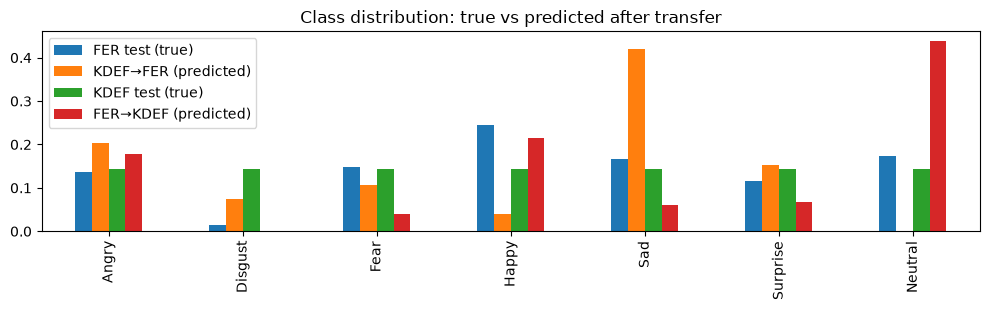

In [6]:
pc = pd.DataFrame({"FER→FER": per_class_f1(yf_te, P[("FER", "FER test")]),
                   "KDEF→FER": per_class_f1(yf_te, P[("KDEF", "FER test")]),
                   "KDEF→KDEF": per_class_f1(yk_te, P[("KDEF", "KDEF test")]),
                   "FER→KDEF": per_class_f1(yk_te, P[("FER", "KDEF test")])})
save_table(pc, "task3_per_class_f1"); display(pc.round(3))

dist = pd.DataFrame({"FER test (true)": np.bincount(yf_te, minlength=7) / len(yf_te),
                     "KDEF→FER (predicted)": np.bincount(P[("KDEF", "FER test")], minlength=7) / len(yf_te),
                     "KDEF test (true)": np.bincount(yk_te, minlength=7) / len(yk_te),
                     "FER→KDEF (predicted)": np.bincount(P[("FER", "KDEF test")], minlength=7) / len(yk_te)}, index=EMO)
save_table(dist, "task3_prediction_distribution")
dist.plot.bar(figsize=(10, 3.2), title="Class distribution: true vs predicted after transfer")
plt.tight_layout(); plt.savefig(FIG_DIR / "task3_prediction_distribution.png"); plt.show()

## 2. Feature transfer
Same classifier type for every feature, hyper-parameters from the source domain's tuning.
The FER source uses a stratified subset (`TR_CROSS`) of the training set to keep the cost low.

In [7]:
TRANSFER_FEATS = ["HOG", "LM", "PCA", "GEO", "HOG+LM"]
for feat in TRANSFER_FEATS:
    Xf_tr_s, yf_tr_s = features("fer_gray", "train", feat)[TR_CROSS], y_fer_tr_full[TR_CROSS]
    Xf_te_s, yf_te_s = domain_data("FER", "test", feat)
    Xk_tr_s, Xk_te_s = features("kdef_m0.2_gray", "train", feat), features("kdef_m0.2_gray", "test", feat)
    fm = fit_final(MODEL, feat, params_for("FER", MODEL, feat), Xf_tr_s, yf_tr_s)
    km = fit_final(MODEL, feat, params_for("KDEF", MODEL, feat), Xk_tr_s, yk_tr)
    for direction, mdl, X, y in [("FER→FER", fm, Xf_te_s, yf_te_s), ("FER→KDEF", fm, Xk_te_s, yk_te),
                                 ("KDEF→KDEF", km, Xk_te_s, yk_te), ("KDEF→FER", km, Xf_te_s, yf_te_s)]:
        log_result("task3_features", y, mdl.predict(X), feature=feat, direction=direction, model=MODEL)
ft = pd.read_csv(RESULTS_DIR / "task3_features.csv")
DIRS = ["FER→FER", "FER→KDEF", "KDEF→KDEF", "KDEF→FER"]
for m in ("macro_f1", "acc"):
    t = save_table(fixed_table(ft, "feature", "direction", m, TRANSFER_FEATS, DIRS), f"task3_features_{m}")
    print(m); display(t.round(3))
t = fixed_table(ft, "feature", "direction", "macro_f1", TRANSFER_FEATS, DIRS)
retention = save_table(pd.DataFrame({"FER→KDEF / KDEF→KDEF": t["FER→KDEF"] / t["KDEF→KDEF"],
                                     "KDEF→FER / FER→FER": t["KDEF→FER"] / t["FER→FER"]}), "task3_features_retention")
print("Fraction of the in-domain macro-F1 kept after transfer:"); display(retention.round(2))

macro_f1


direction,FER→FER,FER→KDEF,KDEF→KDEF,KDEF→FER
feature,,,,
HOG,0.354,0.124,0.577,0.167
LM,0.376,0.431,0.695,0.217
PCA,0.276,0.119,0.689,0.155
GEO,0.339,0.380,0.640,0.305
HOG+LM,0.396,0.294,0.637,0.169


acc


direction,FER→FER,FER→KDEF,KDEF→KDEF,KDEF→FER
feature,,,,
HOG,0.410,0.230,0.571,0.210
LM,0.441,0.474,0.709,0.250
PCA,0.362,0.179,0.694,0.189
GEO,0.430,0.444,0.658,0.346
HOG+LM,0.464,0.362,0.638,0.209


Fraction of the in-domain macro-F1 kept after transfer:


,FER→KDEF / KDEF→KDEF,KDEF→FER / FER→FER
feature,,
HOG,0.22,0.47
LM,0.62,0.58
PCA,0.17,0.56
GEO,0.59,0.90
HOG+LM,0.46,0.43


## 3. How large is the domain shift? (domain classifier)
A logistic regression is trained to predict *which dataset* an image comes from (balanced: 784
KDEF vs 784 FER training images, 5-fold CV). Accuracy 0.5 = indistinguishable distributions,
1.0 = completely separable. This is a proxy of the (H-)divergence used in domain-adaptation theory.

In [8]:
from sklearn.model_selection import cross_val_score
fer_idx = stratified_subset(y_fer_tr_full, len(yk_tr))
for feat in TRANSFER_FEATS:
    Xd = np.vstack([features("fer_gray", "train", feat)[fer_idx], features("kdef_m0.2_gray", "train", feat)])
    yd = np.r_[np.zeros(len(fer_idx)), np.ones(len(yk_tr))]
    acc = cross_val_score(Pipeline([("s", StandardScaler()), ("lr", LogisticRegression(max_iter=2000, C=0.1))]),
                          Xd, yd, cv=5, scoring="accuracy").mean()
    _RESULTS.setdefault("task3_domain_clf", []).append({"feature": feat, "domain_clf_acc": round(acc, 4)})
dom = pd.DataFrame(_RESULTS["task3_domain_clf"]).set_index("feature")
save_table(dom, "task3_domain_classifier"); display(dom)

,domain_clf_acc
feature,
HOG,0.9949
LM,0.9420
PCA,0.9885
GEO,0.7953
HOG+LM,0.9975


## 4. Reducing the domain shift
### 4.1 Crop margin: matching KDEF's framing to FER's
The margin is chosen **without labels**: the mean landmark configuration of the KDEF crops is
compared with the mean FER configuration, and the margin giving the closest geometry wins. All
margins are evaluated too, for completeness.

In [9]:
MARGINS = ["0.0", "0.1", "0.2", "0.3"]
mean_fer = landmarks("fer_gray", "train").mean(axis=0)
geom = {m: float(np.linalg.norm(landmarks(f"kdef_m{m}_gray", "train").mean(axis=0) - mean_fer, axis=1).mean()) for m in MARGINS}
BEST_MARGIN = min(geom, key=geom.get)
print("mean landmark distance to FER (relative units):", {k: round(v, 4) for k, v in geom.items()}, "→ chosen margin", BEST_MARGIN)
for m in MARGINS:
    key = f"kdef_m{m}_gray"
    km = fit_final(MODEL, FEAT, params_for("KDEF", MODEL, FEAT), features(key, "train", FEAT), yk_tr)
    log_result("task3_margin", yf_te, km.predict(domain_data("FER", "test", FEAT)[0]), margin=m, direction="KDEF→FER",
               landmark_distance=round(geom[m], 4))
    log_result("task3_margin", yk_te, fer_model.predict(features(key, "test", FEAT)), margin=m, direction="FER→KDEF",
               landmark_distance=round(geom[m], 4))
mg = pd.read_csv(RESULTS_DIR / "task3_margin.csv")
display(save_table(fixed_table(mg, "margin", "direction", "macro_f1", [float(m) for m in MARGINS], ["FER→KDEF", "KDEF→FER"]),
                   "task3_margin_macro_f1").round(3))

mean landmark distance to FER (relative units): {'0.0': 0.033, '0.1': 0.0634, '0.2': 0.0956, '0.3': 0.1134} → chosen margin 0.0


direction,FER→KDEF,KDEF→FER
margin,,
0.0,0.453,0.225
0.1,0.364,0.205
0.2,0.386,0.169
0.3,0.256,0.168


### 4.2 Adaptation table
| adaptation | targets | what is done |
|---|---|---|
| crop margin | (i) cropping | KDEF re-cropped with the margin chosen in 4.1 |
| eye alignment | (i) alignment | both datasets rotated so the eye line is horizontal (dlib) |
| degradation | (ii) resolution/quality | KDEF images get random blur, noise, contrast changes and JPEG artefacts |
| intensity norm. | (iii) intensity/lighting | per-image z-score + CLAHE on both datasets |
| per-domain std. | features | each domain standardized with its own (unlabelled) statistics |
| CORAL | features | source features re-coloured to the target covariance (Sun et al., 2016) |
| all combined | all | every step above together |

baseline                     done (5s)
crop margin 0.0              done (5s)
eye alignment                done (17s)
KDEF degradation             done (10s)
intensity normalization      done (47s)
per-domain standardization   done (5s)
CORAL                        done (9s)
all combined                 done (49s)
macro_f1


direction,FER→KDEF,KDEF→FER
adaptation,,
baseline,0.294,0.169
crop margin 0.0,0.370,0.225
eye alignment,0.305,0.165
KDEF degradation,0.264,0.210
intensity normalization,0.337,0.139
per-domain standardization,0.376,0.227
CORAL,0.304,0.259
all combined,0.334,0.272


acc


direction,FER→KDEF,KDEF→FER
adaptation,,
baseline,0.362,0.209
crop margin 0.0,0.444,0.236
eye alignment,0.383,0.204
KDEF degradation,0.342,0.245
intensity normalization,0.398,0.210
per-domain standardization,0.424,0.242
CORAL,0.347,0.286
all combined,0.388,0.292


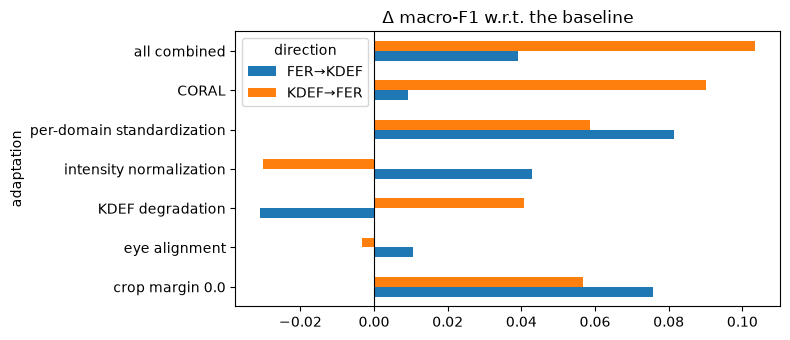

In [10]:
def derive(key, suffix, fn):
    """Create (once) a derived image dataset data/cache/<key><suffix>.npz by applying fn to X."""
    new = f"{key}{suffix}"
    if not (F.CACHE_DIR / f"{new}.npz").exists():
        d = dict(np.load(F.CACHE_DIR / f"{key}.npz", allow_pickle=True))
        for k in [k for k in d if k.startswith("X_")]:
            d[k] = fn(d[k])
        np.savez_compressed(F.CACHE_DIR / f"{new}.npz", **d)
    return new


def intensity_norm(X):
    return F.apply_variant(F.zscore_images(X), "clahe")


def coral(Xs, Xt, eps=1.0):
    """CORAL: whiten the source covariance and re-colour it with the target covariance."""
    def msqrt(C, inv=False):
        w, V = np.linalg.eigh(C)
        w = np.clip(w, 1e-8, None)
        return (V * (w ** (-0.5 if inv else 0.5))) @ V.T
    Cs = np.cov(Xs, rowvar=False) + eps * np.eye(Xs.shape[1])
    Ct = np.cov(Xt, rowvar=False) + eps * np.eye(Xt.shape[1])
    return (Xs - Xs.mean(axis=0)) @ msqrt(Cs, inv=True) @ msqrt(Ct) + Xt.mean(axis=0)


def adapted_data(cfg):
    """Feature matrices for both domains under an adaptation config."""
    fer_key = "fer_aligned" if cfg.get("align") else "fer_gray"
    kdef_key = f"kdef_m{cfg.get('margin', '0.2')}_gray" + ("_aligned" if cfg.get("align") else "")
    if cfg.get("degrade"):
        kdef_key = derive(kdef_key, "_deg", lambda X: F.degrade_batch(X, seed=SEED))
    if cfg.get("intensity"):
        fer_key, kdef_key = derive(fer_key, "_int", intensity_norm), derive(kdef_key, "_int", intensity_norm)
    return {
        "fer_tr": features(fer_key, "train", FEAT)[TR_CROSS], "fer_te": features(fer_key, "test", FEAT)[TE_FER],
        "kdef_tr": features(kdef_key, "train", FEAT), "kdef_te": features(kdef_key, "test", FEAT)}


def feature_align(Xs, Xt_unlabelled, X_test, cfg):
    """Per-domain standardization and/or CORAL. Target statistics come from the target TRAIN split."""
    if cfg.get("domain_std") or cfg.get("coral"):
        s_src, s_tgt = StandardScaler().fit(Xs), StandardScaler().fit(Xt_unlabelled)
        Xs, Xt_unlabelled, X_test = s_src.transform(Xs), s_tgt.transform(Xt_unlabelled), s_tgt.transform(X_test)
    if cfg.get("coral"):
        Xs = coral(Xs, Xt_unlabelled)
    return Xs, X_test


ADAPTATIONS = {
    "baseline": {},
    f"crop margin {BEST_MARGIN}": {"margin": BEST_MARGIN},
    "eye alignment": {"align": True},
    "KDEF degradation": {"degrade": True},
    "intensity normalization": {"intensity": True},
    "per-domain standardization": {"domain_std": True},
    "CORAL": {"coral": True},
    "all combined": {"margin": BEST_MARGIN, "align": True, "degrade": True, "intensity": True, "coral": True},
}
for name, cfg in ADAPTATIONS.items():
    t = time.time()
    D = adapted_data(cfg)
    # KDEF -> FER   (target-domain statistics: FER train images, unlabelled)
    Xs, Xt = feature_align(D["kdef_tr"], D["fer_tr"], D["fer_te"], cfg)
    km = fit_final(MODEL, FEAT, params_for("KDEF", MODEL, FEAT), Xs, yk_tr)
    log_result("task3_adapt", yf_te, km.predict(Xt), adaptation=name, direction="KDEF→FER")
    # FER -> KDEF   (target-domain statistics: KDEF train images, unlabelled)
    Xs, Xt = feature_align(D["fer_tr"], D["kdef_tr"], D["kdef_te"], cfg)
    fm = fit_final(MODEL, FEAT, params_for("FER", MODEL, FEAT), Xs, y_fer_tr_full[TR_CROSS])
    log_result("task3_adapt", yk_te, fm.predict(Xt), adaptation=name, direction="FER→KDEF")
    print(f"{name:28s} done ({time.time() - t:.0f}s)")

ad = pd.read_csv(RESULTS_DIR / "task3_adapt.csv")
for m in ("macro_f1", "acc"):
    t = save_table(fixed_table(ad, "adaptation", "direction", m, list(ADAPTATIONS), ["FER→KDEF", "KDEF→FER"]), f"task3_adapt_{m}")
    print(m); display(t.round(3))
t = fixed_table(ad, "adaptation", "direction", "macro_f1", list(ADAPTATIONS), ["FER→KDEF", "KDEF→FER"])
(t - t.loc["baseline"]).drop("baseline").plot.barh(figsize=(8, 3.5), title="Δ macro-F1 w.r.t. the baseline")
plt.axvline(0, color="k", lw=0.8); plt.tight_layout(); plt.savefig(FIG_DIR / "task3_adaptation_delta.png"); plt.show()

## 5. Summary (auto-generated)

In [11]:
mt = fixed_table(tr, "train", "test", "macro_f1", ["FER", "KDEF"], ["FER test", "KDEF test"])
print(f"Configuration: {MODEL} + {FEAT}")
print(f"In-domain: FER {mt.loc['FER', 'FER test']:.3f}, KDEF {mt.loc['KDEF', 'KDEF test']:.3f} | "
      f"cross: FER→KDEF {mt.loc['FER', 'KDEF test']:.3f}, KDEF→FER {mt.loc['KDEF', 'FER test']:.3f} (macro-F1)")
print("Best transferring feature (KDEF→FER):", fixed_table(ft, "feature", "direction", "macro_f1", TRANSFER_FEATS, DIRS)["KDEF→FER"].idxmax(),
      "| (FER→KDEF):", fixed_table(ft, "feature", "direction", "macro_f1", TRANSFER_FEATS, DIRS)["FER→KDEF"].idxmax())
print("Most separable feature space (domain classifier):", dom.domain_clf_acc.idxmax(), "| least:", dom.domain_clf_acc.idxmin())
print("Best adaptation per direction:", t.drop("baseline").idxmax().to_dict())

Configuration: LR + HOG+LM
In-domain: FER 0.426, KDEF 0.637 | cross: FER→KDEF 0.386, KDEF→FER 0.169 (macro-F1)
Best transferring feature (KDEF→FER): GEO | (FER→KDEF): LM
Most separable feature space (domain classifier): HOG+LM | least: GEO
Best adaptation per direction: {'FER→KDEF': 'per-domain standardization', 'KDEF→FER': 'all combined'}


**Discussion guide.**
* *Adaptations needed to run the model:* KDEF had to be face-cropped, converted to gray,
  resized to 48×48 and passed through the *same* feature extractors; labels mapped
  (`afraid`→Fear); hyper-parameters come from the source domain because no target labels may be used.
* *Domain shift* = the joint distribution P(x, y) differs between training (source) and test
  (target) data. Here mainly **covariate shift** P(x) (framing, resolution, lighting,
  acquisition, posed vs spontaneous expressions) plus **prior shift** P(y) (balanced KDEF vs
  imbalanced FER) and some **concept shift** P(y|x) (posed, exaggerated KDEF expressions vs
  subtle, ambiguous and noisily labelled FER expressions).
* *Why performance degrades:* the classifier learned decision boundaries in regions of feature
  space that the target data do not occupy (see the domain-classifier accuracy); KDEF has only 56
  identities and one lighting condition, so a KDEF model has never seen the variability of FER;
  the class priors differ.
* *Which features transfer best:* compare the retention table — geometry-based features
  (landmarks, geometric ratios) are normalized for position/scale and do not depend on
  lighting, while pixel/PCA features encode the acquisition conditions directly.